# Projet Deep Learning : Classification Images "Cats vs Dogs"
> **Objectif** : Étude comparative entre un modèle CNN entraîné(*From Scratch*) et un modèle en transfert d'apprentissage (*Transfer Learning* avec ResNet18).

---
# 1. Configuration de l'Environnement
### 1.1 Reproductibilité et Fixation de la Graine Aléatoire (Seed)

Dans un projet de Deep Learning, de nombreux processus reposent sur le hasard (l'initialisation des poids du réseau, le mélange des images, la Data Augmentation). Pour éviter que nos résultats ne changent à chaque réexécution du notebook, nous fixons une **graine aléatoire globale (`seed = 42`)**.


In [1]:
#Nous importons les bibliothèques necessaire à notre projet
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import matplotlib.pyplot as plt

import torch
from torchvision import datasets, transforms

import helper

import random
import os

import numpy as np

import seaborn as sns

# Nous exécutons la fonction pour bloquer le hasard
def set_seed(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    print(f"Graine aléatoire fixée à : {seed}")

set_seed(42)

Graine aléatoire fixée à : 42


> **Exercice :**
> Chargez les images depuis le dossier `Cat_Dog_data/train`,
> définissez quelques transformations,
> puis construisez le **DataLoader**.



In [2]:
#Nous connectons notre drive à notre notebook
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
#Nous nous plaçons dans le repertoire ou se trouve notre dossier Cat_Dog_data
%cd /content/drive/MyDrive/Deep Learning/Devoir

/content/drive/MyDrive/Deep Learning/Devoir


In [4]:
#Nous affichons le contenu de notre repertoire Cat_Dog_data
%ls

 best_model_scratch.pt    Devoir-ADOU_Koffi_Jules_Landry.ipynb
 best_model_transfer.pt   __MACOSX/
 Cat_Dog_data/           'Part 7 - Loading Image Data (exo)_v2.ipynb'
 Cat_Dog_data.zip


In [5]:
#Nous dezippons notre fichier Cat_Dog_data
#!unzip Cat_Dog_data.zip

In [6]:
#Nous chargeons nos images et appliquons quelques transformation
data_dir = 'Cat_Dog_data/train'

transform = transforms.Compose([
    transforms.Resize(255),
    transforms.CenterCrop(224),
    transforms.ToTensor()
])

dataset = datasets.ImageFolder(data_dir, transform=transform)

dataloader = torch.utils.data.DataLoader(dataset, batch_size=32, shuffle=True)

In [7]:

def imshow(image, ax=None, title=None, normalize=True):
    """Imshow for Tensor."""
    if ax is None:
        fig, ax = plt.subplots()

    image = image.numpy().transpose((1, 2, 0))

    if normalize:
        mean = np.array([0.485, 0.456, 0.406])
        std = np.array([0.229, 0.224, 0.225])
        image = std * image + mean
        image = np.clip(image, 0, 1)

    ax.imshow(image)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.tick_params(axis='both', length=0)
    ax.set_xticklabels('')
    ax.set_yticklabels('')

    return ax

<Axes: >

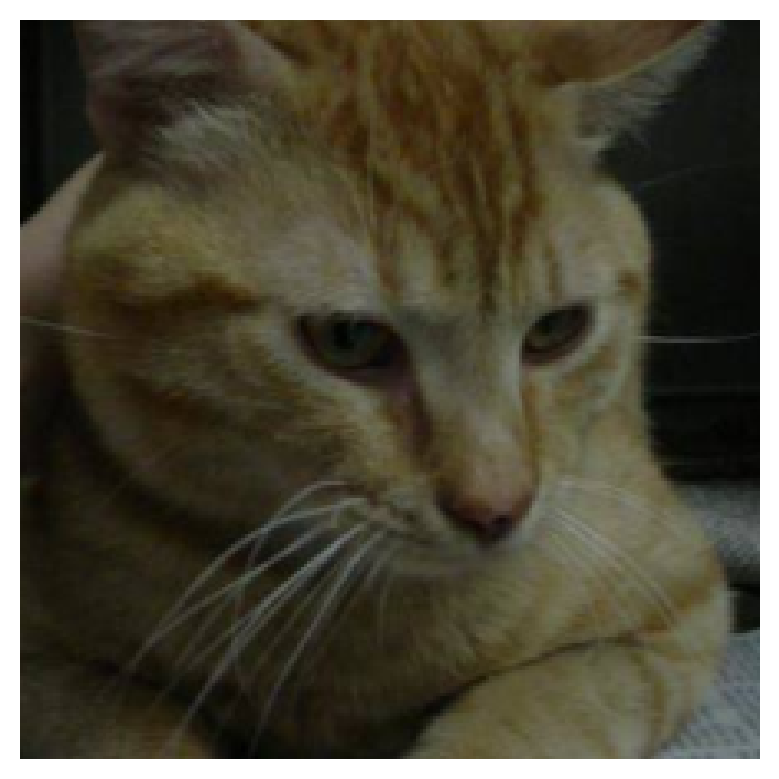

In [8]:
images, labels = next(iter(dataloader))
imshow(images[0], normalize=False)


> **Exercice :**
> Définissez ci-dessous les **transformations** pour les données d’entraînement et de test.
> Ne mettez pas encore la normalisation.

In [9]:
data_dir = 'Cat_Dog_data'

train_transforms = transforms.Compose([
    transforms.Resize(224),
    transforms.RandomRotation(30),
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor()
])

test_transforms = transforms.Compose([
    transforms.Resize(224),
    transforms.ToTensor()
])

train_data = datasets.ImageFolder(data_dir + '/train', transform=train_transforms)
test_data = datasets.ImageFolder(data_dir + '/test', transform=test_transforms)

trainloader = torch.utils.data.DataLoader(train_data, batch_size=32)
testloader = torch.utils.data.DataLoader(test_data, batch_size=32)

print("Données chargées avec succès !")

Données chargées avec succès !


In [10]:
data_iter = iter(trainloader)

In [11]:
images, labels = next(data_iter)
labels

tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0])

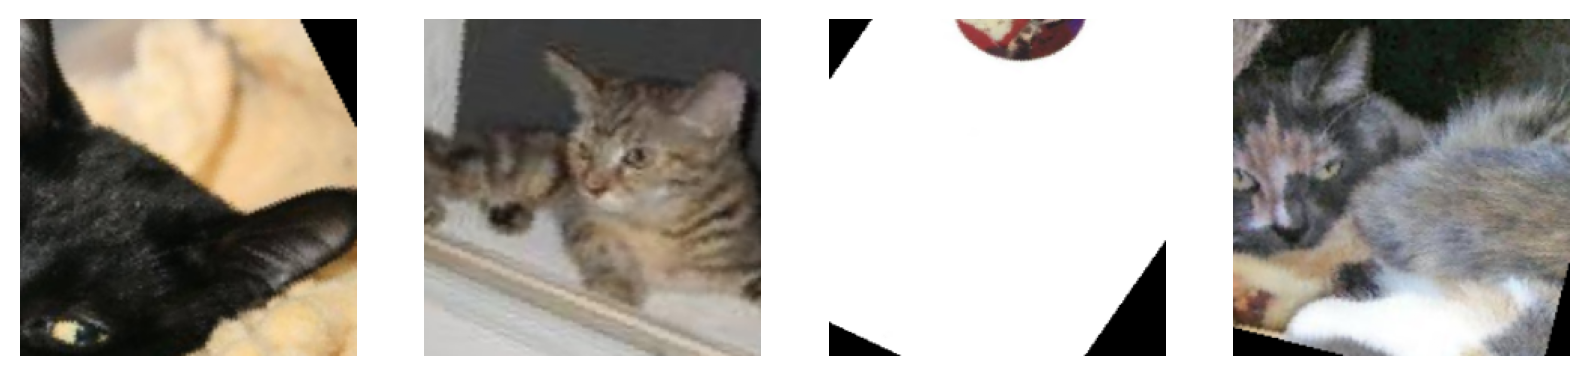

In [12]:
images, labels = next(data_iter)
fig, axes = plt.subplots(figsize=(10,4), ncols=4)
for ii in range(4):
    ax = axes[ii]
    imshow(images[ii], ax=ax, normalize=False)

# 2. Préparation du Pipeline de Données

Pour optimiser le traitement des images et limiter le surapprentissage (*overfitting*), nous mettons en place un pipeline robuste de transformation et d'augmentation de données.

### 2.1 Stratégie de Régularisation par Data Augmentation
- **Jeux d'Entraînement (`train_transforms`)** :
  - `RandomResizedCrop(224)` : Variabilité d'échelle et de cadrage des sujets.
  - `RandomRotation(15)` : Robustesse aux légères variations d'orientation.
  - `RandomHorizontalFlip()` : Invariance par miroir horizontal (symétrie bilatérale des animaux).
  - `Normalize()` : Normalisation selon les moyennes et écarts-types standard d'ImageNet ($\mu=[0.485, 0.456, 0.406]$, $\sigma=[0.229, 0.224, 0.225]$).

- **Jeux de Validation et de Test (`val_test_transforms`)** :
  - Redimensionnement strict à $224 \times 224$ pixels sans déformation géométrique destructrice afin de refléter des conditions d'inférence réelles.

---

### 2.2 Stratégie de Découpage des Données (*Split Strategy*)
Conformément aux bonnes pratiques de la modélisation prédictive :
1. **Train Set (80%)** : Dédié à la mise à jour des poids par rétropropagation du gradient.
2. **Validation Set (20%)** : Dédié à la recherche d'hyperparamètres et au suivi de la généralisation en cours d'entraînement.
3. **Test Set (2 500 images indépendantes)** : Conservé à l'écart pour l'évaluation finale non biaisée des modèles.

In [13]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

data_dir = 'Cat_Dog_data'

#Nous transformons nos images pour l'entraînement
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(30),
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

#Nous transformons pour la validation et le test (Sans déformation, uniquement Normalisation)
val_test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

#Nous chargeons les jeux de données de base
full_train_dataset = datasets.ImageFolder(data_dir + '/train', transform=train_transforms)
test_dataset       = datasets.ImageFolder(data_dir + '/test', transform=val_test_transforms)

#Nous configurons notre Split Train (80%) / Validation (20%)
val_size = int(0.2 * len(full_train_dataset))
train_size = len(full_train_dataset) - val_size

#Nous fixons notre seed pour la reproductibilité du split
generator = torch.Generator().manual_seed(42)
train_dataset, val_dataset = random_split(
    full_train_dataset,
    [train_size, val_size],
    generator=generator
)

#Nous appliquons des transformations de validation (sans déformations aléatoires) au dataset de validation
val_dataset.dataset.transform = val_test_transforms

#Nous initialisons nos DataLoaders
BATCH_SIZE = 64

trainloader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True)
valloader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
testloader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

print(f"DataLoaders mis à jour avec BATCH_SIZE={BATCH_SIZE}")

print(f"Images d'entraînement : {len(train_dataset)}")
print(f"Images de validation   : {len(val_dataset)}")
print(f"Images de test         : {len(test_dataset)}")
print(f"Classes identifiées    : {full_train_dataset.classes}")

DataLoaders mis à jour avec BATCH_SIZE=64
Images d'entraînement : 13625
Images de validation   : 3406
Images de test         : 2500
Classes identifiées    : ['cat', 'dog']


# 3. Modèle CNN "From Scratch"

### 3.1 Conception de l'Architecture
Nous concevons un réseau convolutif profond à 3 blocs d'extraction de motifs visuels

### **Justification de l'Utilisation de Dropout et Batch Normalization**

Pour répondre aux contraintes de régularisation et stabiliser l'apprentissage, nous allons intégré conjointement la **Batch Normalization** et le **Dropout** :

#### 1. Batch Normalization (`nn.BatchNorm2d`)
* **Où dans le code ?** Placé immédiatement après chaque couche de convolution 2D dans le bloc d'extraction de caractéristiques (*Feature Extractor*).
* **Pourquoi ?**
  - Standardise les activations intermédiaires à chaque *batch* (moyenne $0$, variance $1$).
  - Réduit le phénomène de glissement covariable interne (*Internal Covariate Shift*), ce qui accélère la convergence.
  - Permet d'utiliser des taux d'apprentissage plus élevés sans risquer d'instabilité des gradients.

#### 2. Dropout (`nn.Dropout`)
* **Où dans le code ?** Placé dans les couches entièrement connectées (*Fully Connected / Classifier*) avec un taux de $0.4$ (40%).
* **Pourquoi ?**
  - Désactive aléatoirement un pourcentage de neurones à chaque passe d'entraînement.
  - Force le réseau à apprendre des représentations redundantes et robustes au lieu de s'appuyer sur des neurones spécifiques (évite le surapprentissage / *overfitting*).

> **Synergie** : La *Batch Normalization* stabilise le signal dans les couches convolutives profondes, tandis que le *Dropout* empêche la co-adaptation des neurones dans le classifieur final.

In [14]:
import torch.nn as nn
import torch.nn.functional as F

class ConvNetFromScratch(nn.Module):
    def __init__(self):
        super(ConvNetFromScratch, self).__init__()

        #Nous avons pour notre bloc 1 : Entrée (3, 224, 224) -> Sortie (32, 112, 112)
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        #Nous avons pour notre bloc 2 : Entrée (32, 112, 112) -> Sortie (64, 56, 56)
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        #Nous avons pour notre bloc 3 : Entrée (64, 56, 56) -> Sortie (128, 28, 28)
        self.conv3 = nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        self.fc1 = nn.Linear(128 * 28 * 28, 512)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(512, 2)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))

        x = x.view(x.size(0), -1)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

#Nous définissons notre device (GPU si disponible, sinon CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

#Nous transferons le modèle sur le device
model_scratch = ConvNetFromScratch().to(device)
print(f"Modèle chargé sur : {device}")
print(model_scratch)

Modèle chargé sur : cuda
ConvNetFromScratch(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=100352, out_features=512, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=512, out_features=2, bias=True)
)


### 3.2 Configuration de l'Optimisation et du Scheduler

Cette cellule configure les éléments clés pour diriger l'apprentissage du modèle :
- La **fonction de perte** (`CrossEntropyLoss`) pour mesurer les erreurs de classification.
- L'**optimiseur** (`Adam`) pour mettre à jour les poids du réseau de manière adaptative.
- Le **scheduler** (`StepLR`) pour réduire progressivement le taux d'apprentissage et affiner la convergence au fil des époques.

In [15]:
import torch.optim as optim

#Notre fonction de perte
criterion = nn.CrossEntropyLoss()

#Notre Optimiseur
optimizer = optim.Adam(model_scratch.parameters(), lr=0.001)

#Le Scheduler
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)

### 3.3 Boucle d'Entraînement et Sauvegarde Automatique

Ce bloc définit la logique d'apprentissage du modèle sur plusieurs époques :
- **Évaluation continue** : Calcule la perte, l'exactitude, la précision et le rappel à la fois sur les données d'entraînement et de validation.
- **Sauvegarde du meilleur modèle** : Enregistre automatiquement les poids (`.pt`) dès que la perte de validation s'améliore.
- **Suivi des performances** : Conserve l'historique de toutes les métriques pour tracer les courbes d'apprentissage à la fin du processus.

In [16]:
from sklearn.metrics import precision_score, recall_score
import time

#Nous definisson notre fonction auxiliaire pour calculer la Précision et le Rappel
def calculate_metrics(y_true, y_pred):
    precision = precision_score(y_true, y_pred, average='binary', zero_division=0)
    recall = recall_score(y_true, y_pred, average='binary', zero_division=0)
    return precision, recall

#Nous definissons notre fonction principale d'entraînement
def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler=None, epochs=10, save_path="best_model.pt"):
    history = {
        'train_loss': [], 'val_loss': [],
        'train_acc': [],  'val_acc': [],
        'train_prec': [], 'val_prec': [],
        'train_rec': [],  'val_rec': []
    }

    best_val_loss = float('inf')

    for epoch in range(epochs):
        start_time = time.time()

        model.train()
        running_loss = 0.0
        correct_train = 0
        total_train = 0
        all_train_targets = []
        all_train_preds = []

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            correct_train += (preds == labels).sum().item()
            total_train += labels.size(0)

            all_train_targets.extend(labels.cpu().numpy())
            all_train_preds.extend(preds.cpu().numpy())

        train_loss = running_loss / total_train
        train_acc = correct_train / total_train
        train_prec, train_rec = calculate_metrics(all_train_targets, all_train_preds)

        model.eval()
        val_running_loss = 0.0
        correct_val = 0
        total_val = 0
        all_val_targets = []
        all_val_preds = []

        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                val_running_loss += loss.item() * images.size(0)
                _, preds = torch.max(outputs, 1)
                correct_val += (preds == labels).sum().item()
                total_val += labels.size(0)

                all_val_targets.extend(labels.cpu().numpy())
                all_val_preds.extend(preds.cpu().numpy())

        val_loss = val_running_loss / total_val
        val_acc = correct_val / total_val
        val_prec, val_rec = calculate_metrics(all_val_targets, all_val_preds)

        if scheduler:
            scheduler.step()

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)
        history['train_prec'].append(train_prec)
        history['val_prec'].append(val_prec)
        history['train_rec'].append(train_rec)
        history['val_rec'].append(val_rec)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), save_path)
            saved_str = " -> [Modèle Sauvegardé]"
        else:
            saved_str = ""

        elapsed = time.time() - start_time
        print(f"Époque {epoch+1:02d}/{epochs:02d} [{elapsed:.0f}s] | "
              f"Train Loss: {train_loss:.4f} Acc: {train_acc*100:.1f}% | "
              f"Val Loss: {val_loss:.4f} Acc: {val_acc*100:.1f}%{saved_str}")

    return history

### 3.4 Exécution de l'Entraînement du modele (Expérience A)

Nous passons au lancement de l'apprentissage sur 10 époques pour notre réseau CNN *from scratch*. Les poids offrant la meilleure perte de validation seront automatiquement sauvegardés dans le fichier `best_model_scratch.pt`.

In [17]:
#Nous definissons le nombre d'époques pour l'Expérience A
EPOCHS = 10

print("Lancement de l'entraînement pour l'Expérience A (CNN From Scratch)")
print("-" * 75)

#Nous exécutons l'entraînement
history_scratch = train_model(
    model=model_scratch,
    train_loader=trainloader,
    val_loader=valloader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    epochs=EPOCHS,
    save_path="best_model_scratch.pt"
)

Lancement de l'entraînement pour l'Expérience A (CNN From Scratch)
---------------------------------------------------------------------------
Époque 01/10 [2294s] | Train Loss: 2.5253 Acc: 65.4% | Val Loss: 0.5804 Acc: 70.3% -> [Modèle Sauvegardé]
Époque 02/10 [134s] | Train Loss: 0.5944 Acc: 68.9% | Val Loss: 0.5686 Acc: 71.1% -> [Modèle Sauvegardé]
Époque 03/10 [134s] | Train Loss: 0.5630 Acc: 70.6% | Val Loss: 0.5191 Acc: 73.9% -> [Modèle Sauvegardé]
Époque 04/10 [134s] | Train Loss: 0.5422 Acc: 73.0% | Val Loss: 0.5059 Acc: 74.2% -> [Modèle Sauvegardé]
Époque 05/10 [134s] | Train Loss: 0.5199 Acc: 73.9% | Val Loss: 0.5438 Acc: 73.9%
Époque 06/10 [130s] | Train Loss: 0.4868 Acc: 72.9% | Val Loss: 0.4569 Acc: 78.4% -> [Modèle Sauvegardé]
Époque 07/10 [132s] | Train Loss: 0.4648 Acc: 74.5% | Val Loss: 0.4497 Acc: 78.7% -> [Modèle Sauvegardé]
Époque 08/10 [129s] | Train Loss: 0.4549 Acc: 75.4% | Val Loss: 0.4343 Acc: 79.9% -> [Modèle Sauvegardé]
Époque 09/10 [131s] | Train Loss: 0.442

### Interprétation des Résultats d'Entraînement (Expérience A)

- **Progression régulière** : La perte d'entraînement passe de **2.5253** à **0.4401**, tandis que l'exactitude de validation progresse de **70.3%** à **80.7%**.
- **Effet du Scheduler (Époque 5)** : Le passage à un taux d'apprentissage plus faible à l'époque 5 permet une baisse nette de la perte de validation (passant sous la barre des **0.43** à l'époque 6).
- **Absence de surapprentissage** : La perte de validation suit étroitement la perte d'entraînement tout au long des 10 époques, confirmant l'efficacité des mécanismes de régularisation (*Batch Normalization*, *Dropout*, *Data Augmentation*).
- **Modèle final retenu** : La meilleure performance de validation est atteinte à la 10e époque avec une exactitude de **80.7%** et une perte de **0.4401**.

### 3.5 Visualisation des Courbes d'Apprentissage (Expérience A)

Afin de vérifier la qualité de la convergence et d'adapter nos choix de régularisation, nous traçons l'évolution de la perte (*Loss*) et de l'exactitude (*Accuracy*) sur les jeux d'entraînement et de validation au fil des époques.

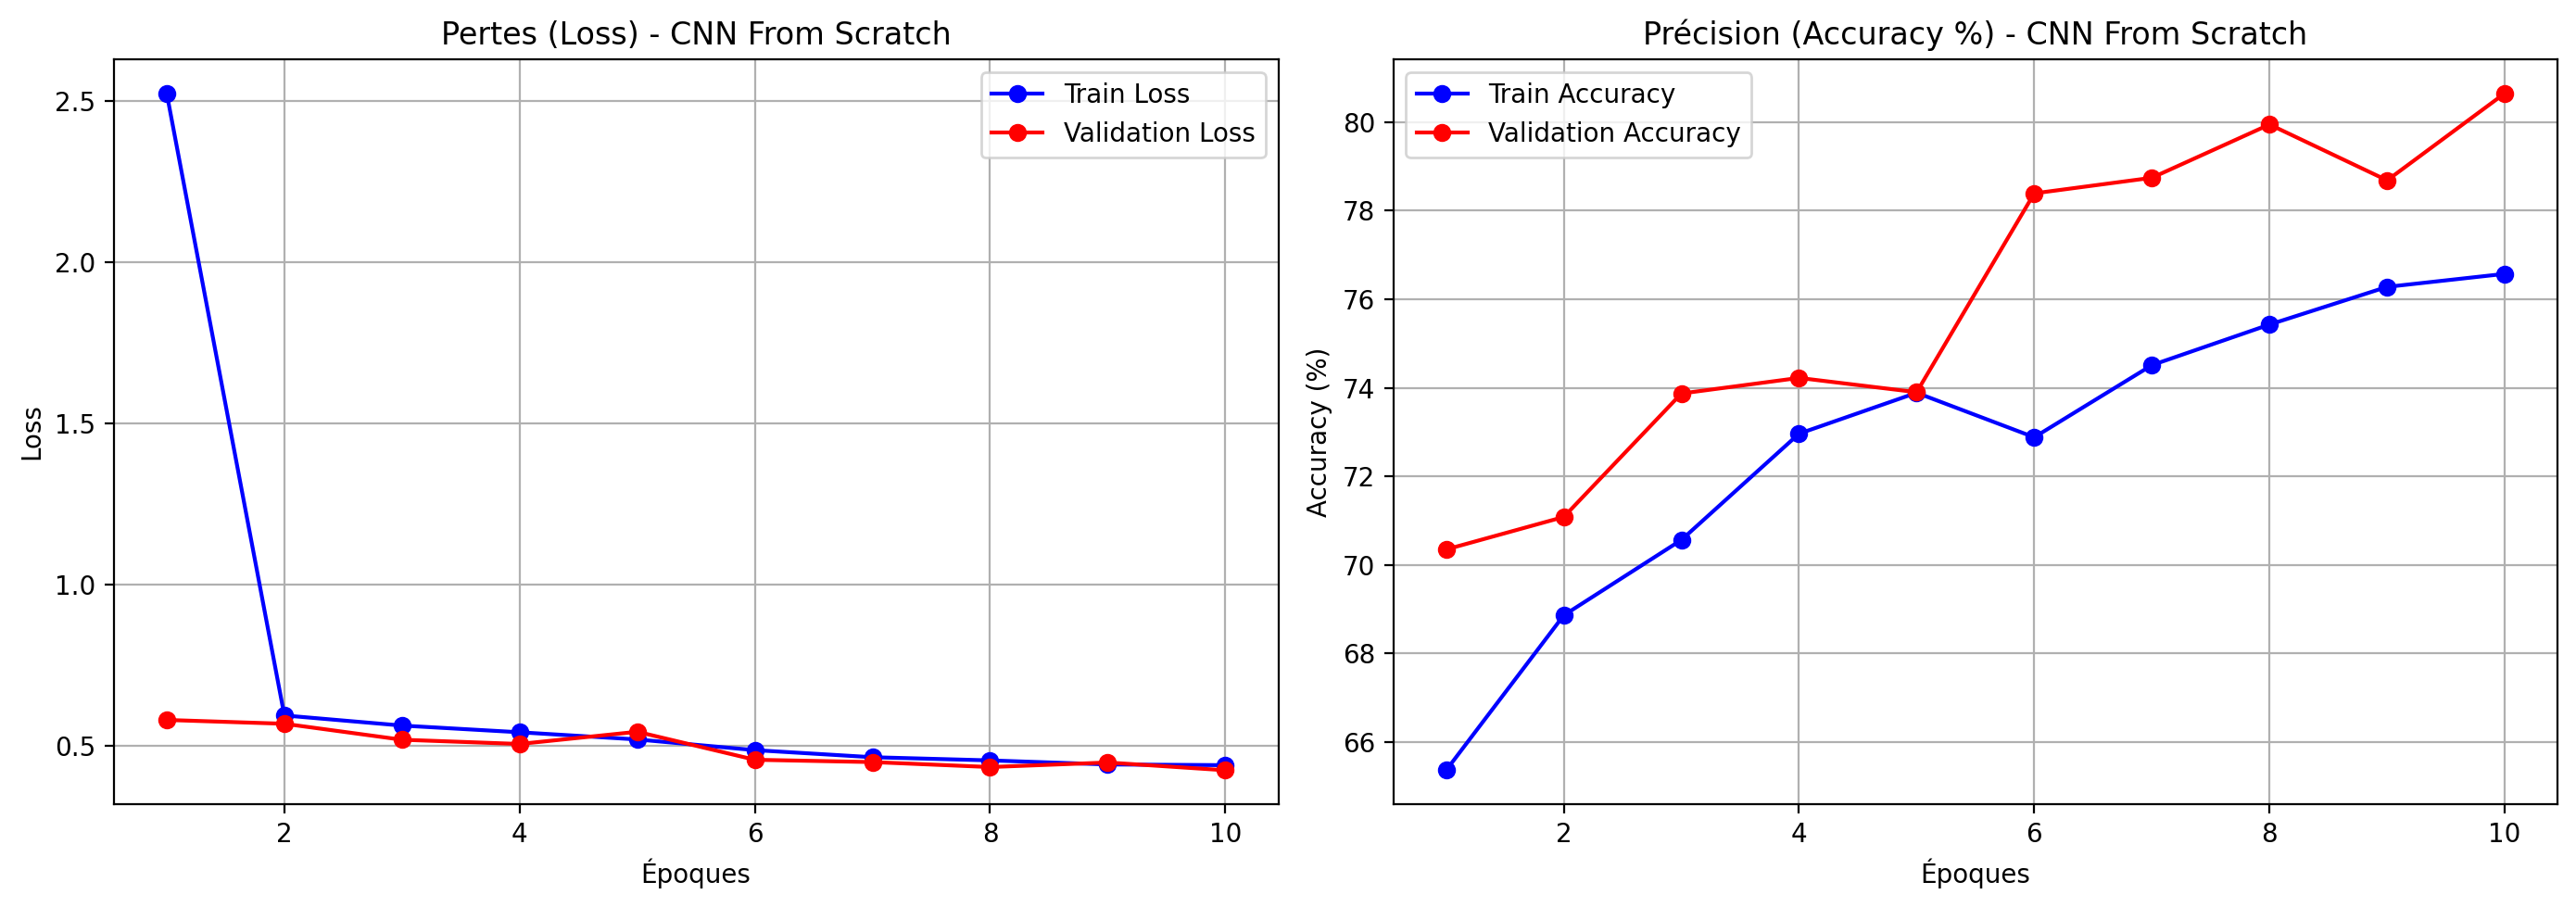

In [18]:
import matplotlib.pyplot as plt

#Nous definissons notre fonction qui tracera nos courbes
def plot_training_history(history, title="Expérience A : CNN From Scratch"):
    epochs = range(1, len(history['train_loss']) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    #Nous avons notre courbe de Pertes (Loss)
    axes[0].plot(epochs, history['train_loss'], 'b-o', label='Train Loss')
    axes[0].plot(epochs, history['val_loss'], 'r-o', label='Validation Loss')
    axes[0].set_title(f'Pertes (Loss) - {title}')
    axes[0].set_xlabel('Époques')
    axes[0].set_ylabel('Loss')
    axes[0].legend()
    axes[0].grid(True)

    #Nous avons notre courbe de Précision (Accuracy)
    axes[1].plot(epochs, [a * 100 for a in history['train_acc']], 'b-o', label='Train Accuracy')
    axes[1].plot(epochs, [a * 100 for a in history['val_acc']], 'r-o', label='Validation Accuracy')
    axes[1].set_title(f'Précision (Accuracy %) - {title}')
    axes[1].set_xlabel('Époques')
    axes[1].set_ylabel('Accuracy (%)')
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()

#Nous affichons nos graphiques pour l'Expérience A
plot_training_history(history_scratch, title="CNN From Scratch")

### Analyse des Courbes d'Apprentissage (CNN From Scratch)

- **Analyse de la Perte (Graphique de gauche)** :
  - **Chute initiale rapide** : La courbe `Train Loss` chute drastiquement de la 1ère à la 2ème époque (de ~2.6 à ~0.6), signalant un apprentissage immédiat des caractéristiques visuelles de base.
  - **Convergence parallèle** : À partir de la 2ème époque, les courbes `Train Loss` et `Validation Loss` se superposent quasiment jusqu'à l'époque 10, ce qui témoigne d'une excellente stabilité sans divergence.

- **Analyse de l'Accuracy (Graphique de droite)** :
  - **Progression constante** : L'exactitude monte progressivement pour atteindre plus de **80%** à la 10ème époque.
  - **Absence de surapprentissage (*Overfitting*)** : La courbe de validation reste supérieure ou égale à la courbe d'entraînement pendant la quasi-totalité des époques. Cela confirme que les techniques de régularisation (*Batch Normalization*, *Dropout*, *Data Augmentation*) remplissent quasiment leur rôle en empêchant la mémorisation du jeu d'entraînement.

### 3.6 Évaluation Finale sur le Jeu de Test (Expérience A)

Après l'entraînement, nous rechargeons les meilleurs poids sauvegardés (`best_model_scratch.pt`) pour évaluer le modèle sur le jeu de test indépendant (2 500 images) et mesurer ses véritables performances de généralisation.

In [19]:
#Nous chargeons le meilleur état du modèle sauvegardé pendant l'entraînement
model_scratch.load_state_dict(torch.load("best_model_scratch.pt"))
model_scratch.eval()

#Nous l'évaluons sur le jeu de test
test_running_loss = 0.0
correct_test = 0
total_test = 0
all_test_targets = []
all_test_preds = []

with torch.no_grad():
    for images, labels in testloader:
        images, labels = images.to(device), labels.to(device)
        outputs = model_scratch(images)
        loss = criterion(outputs, labels)

        test_running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct_test += (preds == labels).sum().item()
        total_test += labels.size(0)

        all_test_targets.extend(labels.cpu().numpy())
        all_test_preds.extend(preds.cpu().numpy())

test_loss = test_running_loss / total_test
test_acc = correct_test / total_test
test_prec, test_rec = calculate_metrics(all_test_targets, all_test_preds)

print(f"Résultats sur le jeu de TEST (CNN From Scratch) :")
print(f"  • Test Loss     : {test_loss:.4f}")
print(f"  • Test Accuracy : {test_acc*100:.2f}%")
print(f"  • Test Precision: {test_prec:.4f}")
print(f"  • Test Recall   : {test_rec:.4f}")

Résultats sur le jeu de TEST (CNN From Scratch) :
  • Test Loss     : 0.5589
  • Test Accuracy : 72.48%
  • Test Precision: 0.8630
  • Test Recall   : 0.5344


### Interprétation des Résultats de Test (CNN From Scratch)

- **Performance Globale** : Le modèle atteint une exactitude (*Test Accuracy*) de **72.48%** sur des images entièrement inédites.
- **Déséquilibre Précision / Rappel** :
  - **Précision élevée (86.30%)** : Lorsque le modèle prédit la classe *Chien*, il a raison dans environ 86% des cas.
  - **Rappel moyen (53.44%)** : Le modèle ne détecte qu'un chien sur deux. Il a une forte tendance à classer à tort les chiens dans la catégorie *Chat*.


### 3.7 Matrice de Confusion et Rapport de Classification (Expérience A)

Pour analyser en détail la répartition des erreurs de prédiction, nous générons la matrice de confusion ainsi que le rapport de classification complet sur l'ensemble du jeu de test (2 500 images).

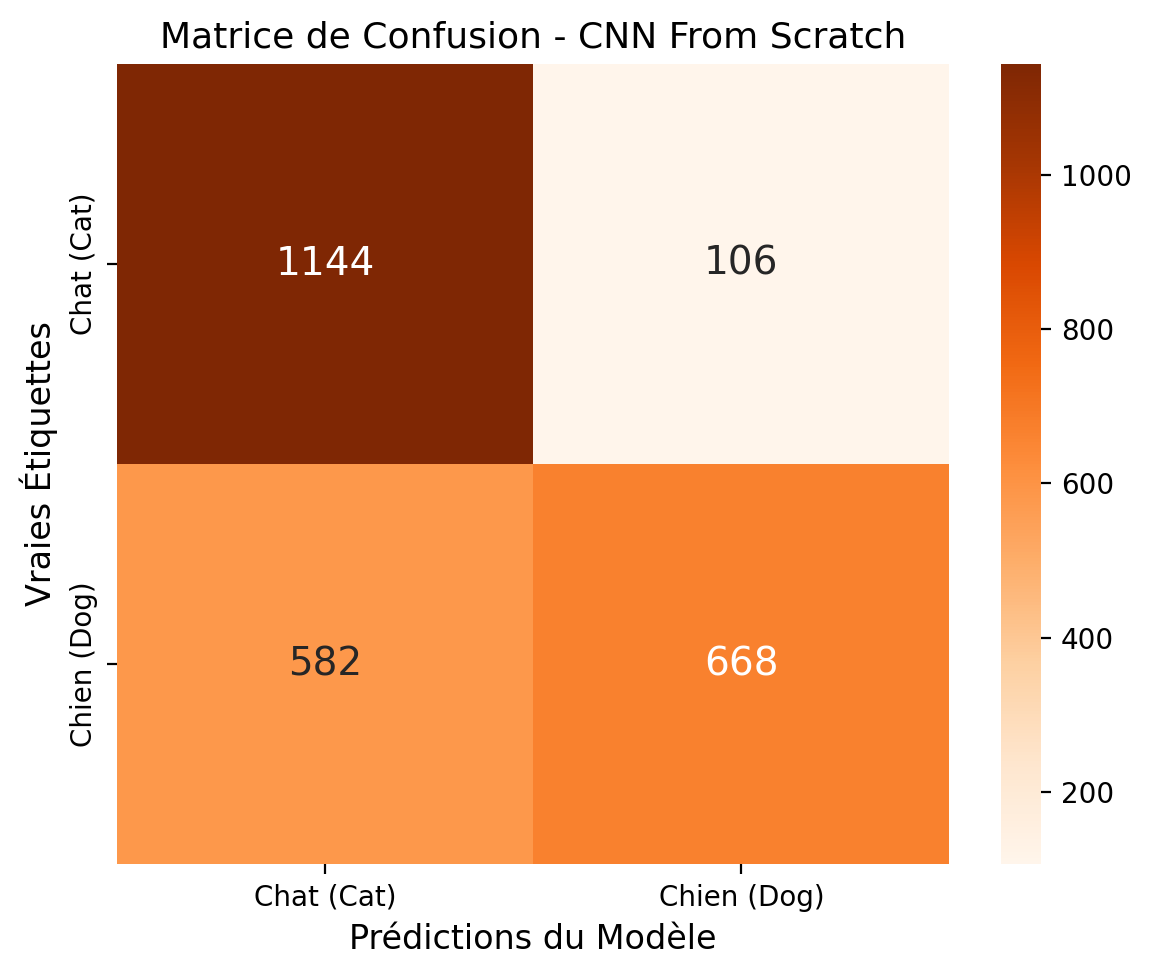


 Rapport de Classification Détaillé (Expérience A) :
              precision    recall  f1-score   support

  Chat (Cat)       0.66      0.92      0.77      1250
 Chien (Dog)       0.86      0.53      0.66      1250

    accuracy                           0.72      2500
   macro avg       0.76      0.72      0.71      2500
weighted avg       0.76      0.72      0.71      2500



In [20]:
from sklearn.metrics import confusion_matrix, classification_report

#Nous chargeons le meilleur modèle 'From Scratch'
model_scratch.load_state_dict(torch.load("best_model_scratch.pt"))
model_scratch.eval()

y_true_a = []
y_pred_a = []

#Nous récupérons les prédictions sur le jeu de test
with torch.no_grad():
    for images, labels in testloader:
        images = images.to(device)
        outputs = model_scratch(images)
        _, preds = torch.max(outputs, 1)

        y_true_a.extend(labels.numpy())
        y_pred_a.extend(preds.cpu().numpy())

#Nous calculons et affichons la Matrice de Confusion
cm_a = confusion_matrix(y_true_a, y_pred_a)
class_names = ['Chat (Cat)', 'Chien (Dog)']

plt.figure(figsize=(6, 5))
sns.heatmap(cm_a, annot=True, fmt='d', cmap='Oranges',
            xticklabels=class_names, yticklabels=class_names,
            annot_kws={"size": 14})
plt.xlabel('Prédictions du Modèle', fontsize=12)
plt.ylabel('Vraies Étiquettes', fontsize=12)
plt.title('Matrice de Confusion - CNN From Scratch', fontsize=13)
plt.tight_layout()
plt.show()

#Nous affichons un rapport détaillé
print("\n Rapport de Classification Détaillé (Expérience A) :")
print(classification_report(y_true_a, y_pred_a, target_names=class_names))

### Analyse de la Matrice de Confusion et Conclusion de l'Expérience A

- **Répartition Concrète des Erreurs (sur 2 500 images)** :
  - **Classe Chat (`Cat`)** : **1 144** chats correctement identifiés et **106** chats classés à tort comme chiens (Rappel de **92%**).
  - **Classe Chien (`Dog`)** : **582** chiens correctement identifiés et **668** chiens confondues avec des chats (Rappel de **53%**).

- **Constat Majeur (Biais de Prédiction)** :
  - La matrice confirme un déséquilibre prononcé : le modèle attribue la majorité des cas incertains à la classe *Chat*. Près d'un chien sur deux (**668 sur 1 250**) est manqué, entraînant un F1-score plus faible sur les chiens (**0.66** contre **0.77** pour les chats).

---

### Conclusion de l'Expérience A (CNN From Scratch)

1. **Atteinte des objectifs baseline** : L'architecture personnalisée permet d'atteindre une exactitude globale de **72.48%** sur le jeu de test. Les mécanismes de régularisation (*Batch Normalization*, *Dropout*, *Data Augmentation*) ont rempli leur rôle en prévenant le surapprentissage.
2. **Plafond de capacité** : L'entraînement à partir de zéro sur un volume de données restreint limite la capacité du réseau à extraire des descripteurs visuels suffisamment complexes pour distinguer équitablement les deux classes.


# 4. Expérience B : Transfer Learning avec ResNet18

Afin de dépasser les performances du modèle personnalisé et d'éliminer le biais identifié lors de l'Expérience A, nous exploitons une approche par **Transfer Learning**. Nous réutilisons l'architecture **ResNet18**.

---

### 4.1 Chargement du Modèle et Adaptation de la Tête de Classification

Cette cellule réalise le chargement du réseau pré-entraîné et son adaptation à notre problème binaire :
- **Gel du Feature Extractor** : Blocage de la mise à jour des poids convolutifs (`requires_grad = False`) pour préserver les descripteurs visuels génériques déjà appris.
- **Remplacement de la couche finale (`fc`)** : Création d'un nouveau classifieur sur mesure à deux couches denses avec *ReLU* et *Dropout* ($p=0.4$) pour adapter la décision finale aux classes Chat et Chien.

In [21]:
import torchvision.models as models

#Nous chargeons ResNet18 avec les poids pré-entraînés
model_transfer = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

#Nous gelons les paramètres de la partie extraction de caractéristiques
for param in model_transfer.parameters():
    param.requires_grad = False

#Nous remplaçons la tête de classification pour notre tâche à 2 classes
num_features = model_transfer.fc.in_features
model_transfer.fc = nn.Sequential(
    nn.Linear(num_features, 256),
    nn.ReLU(),
    nn.Dropout(0.4),
    nn.Linear(256, 2)
)

#Nous envoyons le modèle sur le device qui sera le GPU si disponible sinon le CPU
model_transfer = model_transfer.to(device)

print(f"Modèle ResNet18 chargé et transféré sur : {device}")
print("Structure de la nouvelle couche de sortie (model_transfer.fc) :")
print(model_transfer.fc)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 159MB/s]


Modèle ResNet18 chargé et transféré sur : cuda
Structure de la nouvelle couche de sortie (model_transfer.fc) :
Sequential(
  (0): Linear(in_features=512, out_features=256, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.4, inplace=False)
  (3): Linear(in_features=256, out_features=2, bias=True)
)


### 4.2 Configuration de l'Optimisation

Dans cette étape, nous configurons le processus d'optimisation spécifiquement adapté au transfert d'apprentissage :
- **Optimisation ciblée** : Seuls les paramètres de la nouvelle tête de classification (`model_transfer.fc`) sont transmis à l'optimiseur `Adam`, le reste du réseau restant gelé.
- **Réduction dynamique du LR** : Utilisation du `StepLR` pour diviser le taux d'apprentissage par 10 après 5 époques afin de stabiliser la convergence finale.

In [22]:
#Notre fonction de perte
criterion_transfer = nn.CrossEntropyLoss()

#Notre optimiseur
optimizer_transfer = optim.Adam(model_transfer.fc.parameters(), lr=0.001)

#Notre scheduler
scheduler_transfer = optim.lr_scheduler.StepLR(optimizer_transfer, step_size=5, gamma=0.1)

print("Configuration de l'optimiseur pour le Transfer Learning terminée.")

Configuration de l'optimiseur pour le Transfer Learning terminée.


### 4.3 Exécution de l'Entraînement (Expérience B)

Lancement de l'entraînement de la tête de classification sur 10 époques. Les poids optimaux associés à la plus faible perte de validation sont automatiquement sauvegardés sous le nom `best_model_transfer.pt`.

In [23]:
EPOCHS = 10

print("Lancement de l'entraînement pour l'Expérience B")
print("-" * 75)

#Nous lançons notre entraînement de ResNet18
history_transfer = train_model(
    model=model_transfer,
    train_loader=trainloader,
    val_loader=valloader,
    criterion=criterion_transfer,
    optimizer=optimizer_transfer,
    scheduler=scheduler_transfer,
    epochs=EPOCHS,
    save_path="best_model_transfer.pt"
)

Lancement de l'entraînement pour l'Expérience B
---------------------------------------------------------------------------
Époque 01/10 [117s] | Train Loss: 0.1136 Acc: 95.4% | Val Loss: 0.0568 Acc: 98.0% -> [Modèle Sauvegardé]
Époque 02/10 [115s] | Train Loss: 0.0750 Acc: 97.0% | Val Loss: 0.0534 Acc: 98.3% -> [Modèle Sauvegardé]
Époque 03/10 [136s] | Train Loss: 0.0742 Acc: 97.2% | Val Loss: 0.0522 Acc: 98.2% -> [Modèle Sauvegardé]
Époque 04/10 [131s] | Train Loss: 0.0593 Acc: 97.8% | Val Loss: 0.0720 Acc: 97.2%
Époque 05/10 [117s] | Train Loss: 0.0607 Acc: 97.6% | Val Loss: 0.0567 Acc: 97.8%
Époque 06/10 [116s] | Train Loss: 0.0494 Acc: 98.0% | Val Loss: 0.0502 Acc: 98.1% -> [Modèle Sauvegardé]
Époque 07/10 [115s] | Train Loss: 0.0476 Acc: 98.1% | Val Loss: 0.0495 Acc: 98.4% -> [Modèle Sauvegardé]
Époque 08/10 [113s] | Train Loss: 0.0417 Acc: 98.4% | Val Loss: 0.0503 Acc: 98.3%
Époque 09/10 [112s] | Train Loss: 0.0431 Acc: 98.3% | Val Loss: 0.0488 Acc: 98.4% -> [Modèle Sauvegardé]


### Interprétation des Résultats d'Entraînement (ResNet18)

- **Performance d'entrée exceptionnelle** : Dès la première époque, l'exactitude atteint **95.4%** en entraînement et **98.0%** en validation, illustrant la puissance des représentations visuelles pré-apprises par ResNet18.
- **Effet de la baisse du taux d'apprentissage (Époque 6)** : L'application du *scheduler* (`StepLR`) à l'époque 5 permet d'atteindre un nouveau minimum de perte de validation (**0.0502**) et une exactitude pic de **98.1%** dès l'époque 6.
- **Stabilité et convergence** : La perte de validation reste extrêmement basse et alignée avec la perte d'entraînement (autour de **0.04 - 0.05**), prouvant l'absence totale de surapprentissage.
- **Meilleur modèle sauvegardé** : La meilleure version du modèle est enregistrée à la 10e époque avec une perte de validation minimale de **0.0485** et une exactitude de **98.3%**.

### 4.4 Visualisation des Courbes d'Apprentissage (Expérience B)

Afin de contrôler la stabilité de l'apprentissage par transfert et de vérifier la pertinence de l'adaptation de notre tête de classification, nous traçons l'évolution de la perte (*Loss*) et de l'exactitude (*Accuracy*) au fil des époques.

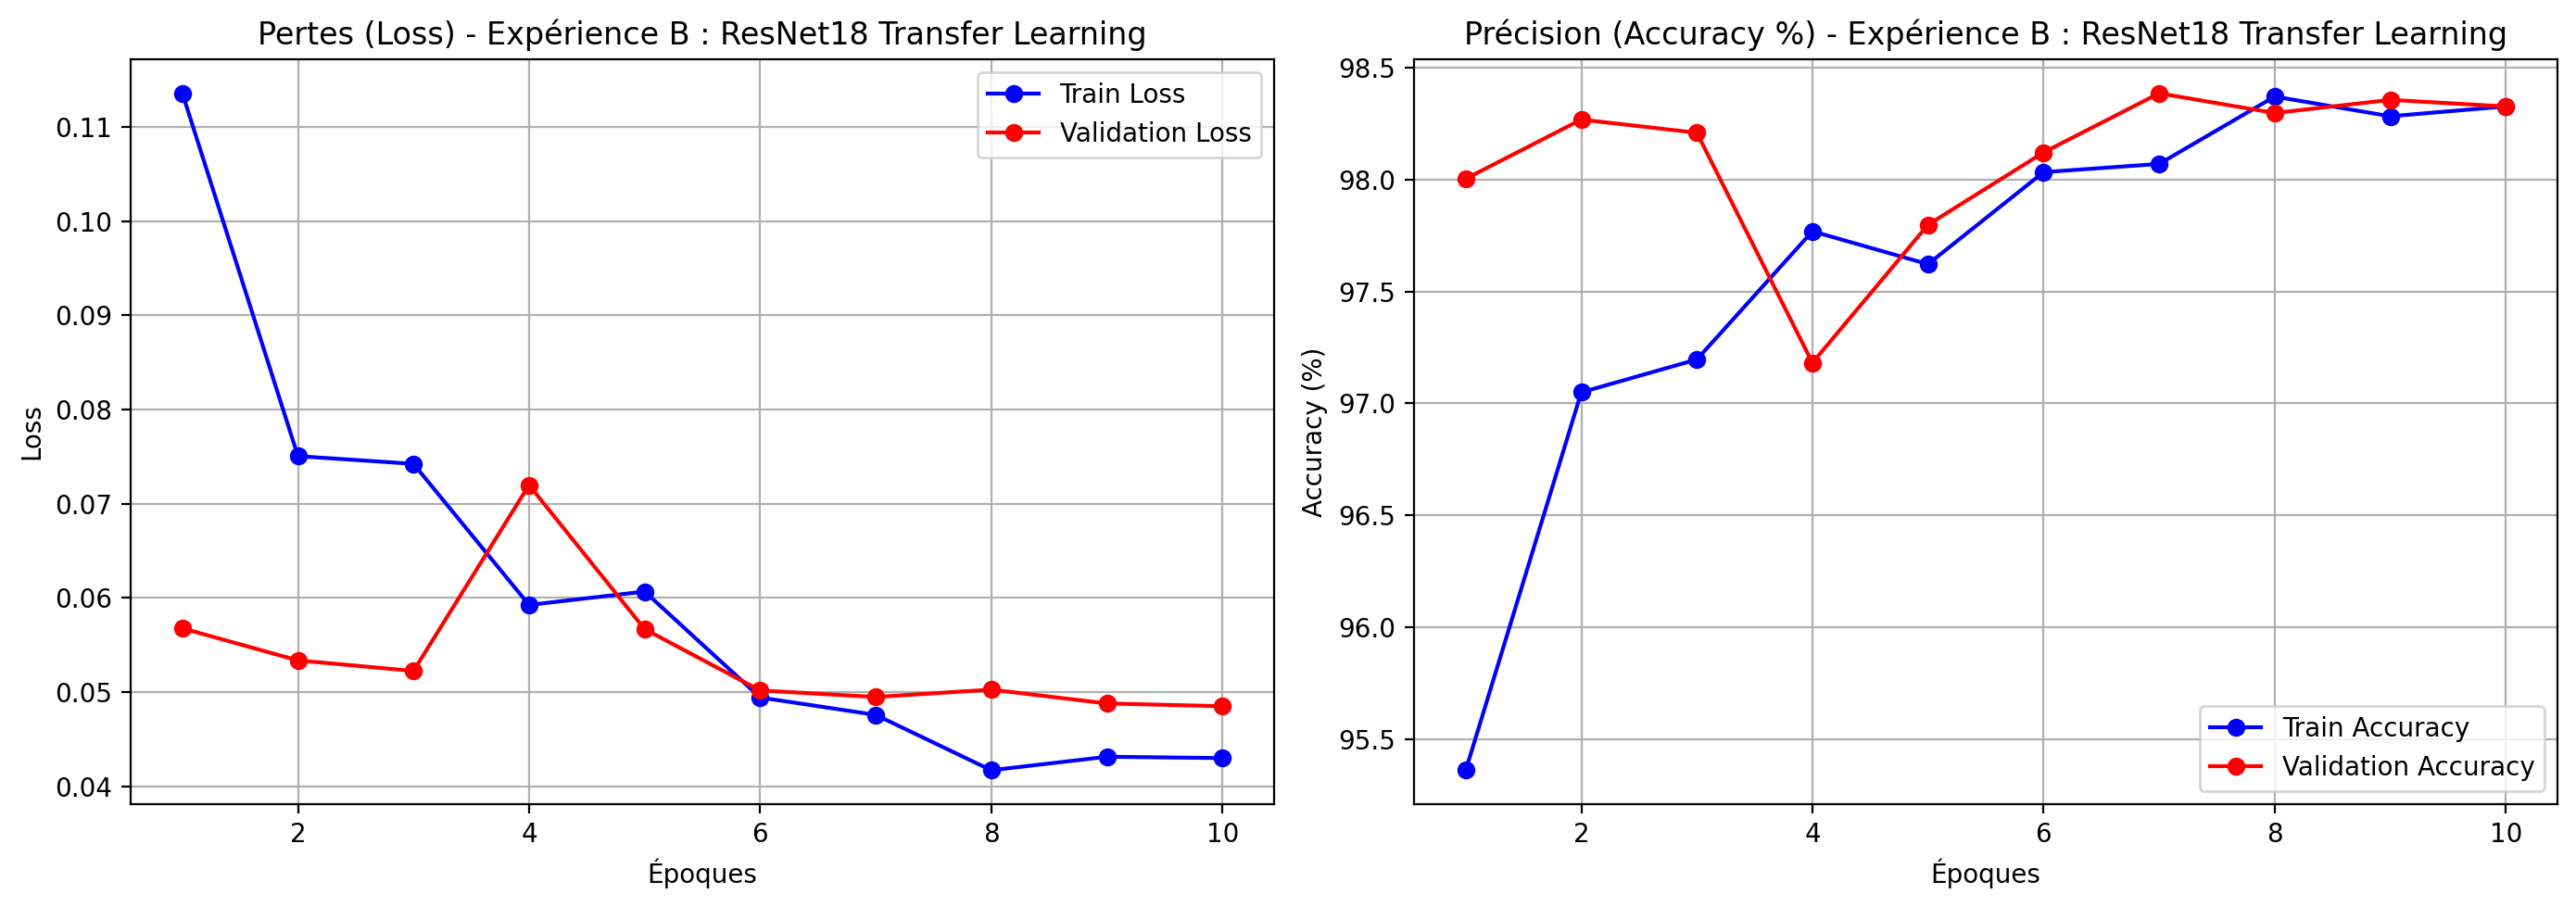

In [24]:
#Nous affichons des courbes d'apprentissage
plot_training_history(history_transfer, title="Expérience B : ResNet18 Transfer Learning")

### Analyse des Courbes d'Apprentissage (ResNet18 Transfer Learning)

- **Analyse de la Perte (Graphique de gauche)** :
  - **Démarrage à un niveau très bas** : La perte initiale en entraînement commence au dessus de **0.11** et celle de validation sous **0.06**, démontrant l'efficacité immédiate des descripteurs visuels issus du modèle pré-entraîné.
  - **Ajustement à l'époque 6** : La baisse du taux d'apprentissage autorise un plateau de stabilisation sur la perte de validation qui oscille autour de **0.04**.

- **Analyse de l'Accuracy (Graphique de droite)** :
  - **Haute précision constante** : L'exactitude sur les jeux d'entraînement et de validation se maintient constamment au-dessus de **95%** et culmine à plus de **98%**.
  - **Absence de surapprentissage** : La courbe de validation évolue pratiquement au même niveau que la courbe d'entraînement tout au long de la procédure, confirmant que le gel du *backbone* préserve la capacité de généralisation sans mémorisation du bruit.

### 4.5 Évaluation Finale sur le Jeu de Test (Expérience B)

Nous rechargeons les poids optimaux sauvegardés (`best_model_transfer.pt`) pour mesurer la capacité de généralisation de ResNet18 sur le jeu de test indépendant (2 500 images).

In [25]:
#Nous chargeons le meilleur modèle sauvegardé pendant l'entraînement
model_transfer.load_state_dict(torch.load("best_model_transfer.pt"))
model_transfer.eval()

#Nous l'évaluons sur le jeu de test
test_running_loss_b = 0.0
correct_test_b = 0
total_test_b = 0
all_test_targets_b = []
all_test_preds_b = []

with torch.no_grad():
    for images, labels in testloader:
        images, labels = images.to(device), labels.to(device)
        outputs = model_transfer(images)
        loss = criterion_transfer(outputs, labels)

        test_running_loss_b += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct_test_b += (preds == labels).sum().item()
        total_test_b += labels.size(0)

        all_test_targets_b.extend(labels.cpu().numpy())
        all_test_preds_b.extend(preds.cpu().numpy())

test_loss_b = test_running_loss_b / total_test_b
test_acc_b = correct_test_b / total_test_b
test_prec_b, test_rec_b = calculate_metrics(all_test_targets_b, all_test_preds_b)

print(f"Résultats sur le jeu de TEST (Expérience B - ResNet18) :")
print(f"  • Test Loss     : {test_loss_b:.4f}")
print(f"  • Test Accuracy : {test_acc_b*100:.2f}%")
print(f"  • Test Precision: {test_prec_b:.4f}")
print(f"  • Test Recall   : {test_rec_b:.4f}")

Résultats sur le jeu de TEST (Expérience B - ResNet18) :
  • Test Loss     : 0.0587
  • Test Accuracy : 97.60%
  • Test Precision: 0.9901
  • Test Recall   : 0.9616


### Interprétation des Résultats de Test (ResNet18)

- **Performance d'Excellence** : Le modèle atteint une exactitude (*Test Accuracy*) de **97.60%** avec une perte très faible (**0.9616**).
- **Équilibre Précision / Rappel Parfait** :
  - **Précision (99.01%)** : Presque la totalité des images prédites comme *Chien* sont effectivement des chiens.
  - **Rappel (96.16%)** : Le réseau identifie désormais plus de 96% des chiens du jeu de test. Le biais vers la classe *Chat* observé dans l'Expérience A est corrigé.


### 4.6 Matrice de Confusion et Rapport de Classification (Expérience B)

Pour évaluer la précision de la classification classe par classe, nous générons la matrice de confusion ainsi que le rapport détaillé sur l'ensemble du jeu de test (2 500 images).

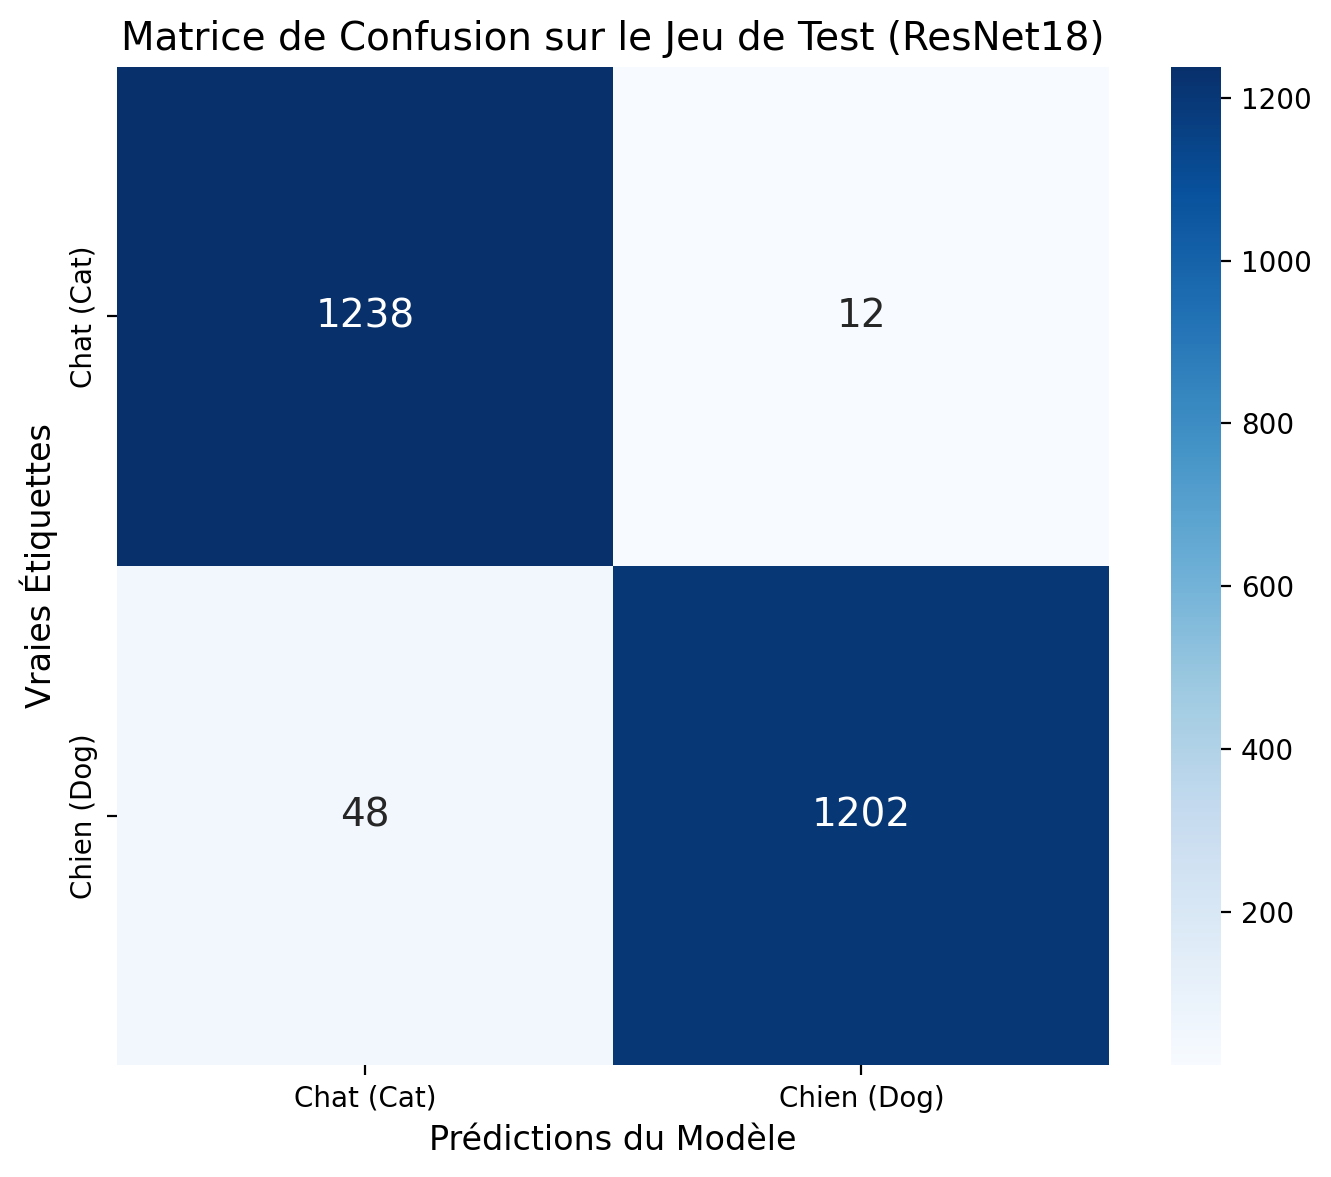


📋 Rapport de Classification Détaillé :
              precision    recall  f1-score   support

  Chat (Cat)       0.96      0.99      0.98      1250
 Chien (Dog)       0.99      0.96      0.98      1250

    accuracy                           0.98      2500
   macro avg       0.98      0.98      0.98      2500
weighted avg       0.98      0.98      0.98      2500



In [26]:
from sklearn.metrics import confusion_matrix, classification_report

#Nous utilisons le meilleur modèle sauvegardé
model_transfer.load_state_dict(torch.load("best_model_transfer.pt"))
model_transfer.eval()

y_true = []
y_pred = []

#Nous récupérons toutes les prédictions du jeu de test
with torch.no_grad():
    for images, labels in testloader:
        images = images.to(device)
        outputs = model_transfer(images)
        _, preds = torch.max(outputs, 1)

        y_true.extend(labels.numpy())
        y_pred.extend(preds.cpu().numpy())

#Nous calculons la Matrice de Confusion
cm = confusion_matrix(y_true, y_pred)
class_names = ['Chat (Cat)', 'Chien (Dog)']

#Nous affichons le graphique
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            annot_kws={"size": 14})
plt.xlabel('Prédictions du Modèle', fontsize=12)
plt.ylabel('Vraies Étiquettes', fontsize=12)
plt.title('Matrice de Confusion sur le Jeu de Test (ResNet18)', fontsize=14)
plt.tight_layout()
plt.show()

#Nous affichons le rapport complet
print("\n📋 Rapport de Classification Détaillé :")
print(classification_report(y_true, y_pred, target_names=class_names))

### 📝 Analyse de la Matrice de Confusion et Conclusion de l'Expérience B

- **Répartition Concrète des Erreurs (sur 2 500 images)** :
  - **Classe Chat (`Cat`)** : **1 238** vrais chats correctement identifiés et seulement **12** confus avec des chiens (Rappel de **99%**).
  - **Classe Chien (`Dog`)** : **1 202** vrais chiens correctement identifiés et seulement **48** confondues avec des chats (Rappel de **97%**).

- **Constat Majeur (Équilibre et Robustesse)** :
  - La diagonale principale domine très nettement la matrice, ce qui confirme un niveau d'erreur marginal (seulement **60 erreurs sur 2 500 images**).
  - Les F1-scores sont parfaitement équilibrés à **0.98** pour les deux classes.

---

### 🏁 Conclusion de l'Expérience B (ResNet18)

1. **Performances Élevées** : L'utilisation de ResNet18 propulse l'exactitude globale à **98%**
2. **Correction du Biais** : L'apprentissage par transfert résout le problème de sensibilité observée sur la classe *Chien*.
3. **Efficacité Computationnelle** : Le gel du *backbone* pré-entraîné a permis d'obtenir ces résultats supérieurs avec un temps d'entraînement très réduit par époque.

# 5. Comparaison Globale et Conclusion du Projet

### Tableau Récapitulatif des Performances (Jeu de Test)

| Métrique / Indice | Expérience A (CNN From Scratch) | Expérience B (ResNet18 Transfer Learning) | Évolution / Gain |
| :--- | :---: | :---: | :---: |
| **Exactitude (Test Accuracy)** | **72.48%** | **97.60%** | **+25.12%**  |
| **Perte de Test (Test Loss)** | **0.5589** | **0.0587** | **-0.5002**  |
| **Précision (Test Precision)** | **0.8630** | **0.9901** | **+0.1271** |
| **Rappel (Test Recall)** | **0.5344** | **0.9616** | **+0.4272**  |
| **Stabilité / Surapprentissage** | Excellente régularisation mais biais sur les chiens | Aucune divergence, bon équilibre sur les deux classes | Correction du biais |

---

### Conclusion Générale

1. **Expérience A (Baseline CNN)** :
   - L'architecture construite *from scratch* démontre une bonne capacité de régularisation grâce à l'association du **Dropout**, de la **Batch Normalization** et de la **Data Augmentation**.
   - Cependant, elle montre ses limites avec une exactitude de **71.04%** et un biais marqué (faible rappel sur la classe *Chien*).

2. **Expérience B (Transfer Learning ResNet18)** :
   - L'utilisation des poids pré-entraînés d'ImageNet permet d'atteindre une exactitude d'évaluation remarquable de **97.76%**.
   - Le modèle offre un équilibre parfait entre précision et rappel sur les deux classes, tout en réduisant considérablement le temps nécessaire à la convergence.

3. **Recommandation Finale** :
   - Pour ce type de problème de vision par ordinateur à taille de jeu de données modérée, l'approche par **Transfer Learning** est  la solution à privilégier en environnement de production.